# 02 — Modelagem e Avaliação

Continua do notebook 01. Toda a lógica vive em `src/phishing/`; este notebook
só chama as funções e interpreta os resultados — assim o que está aqui é
exatamente o que o `python -m phishing.train` executa.

**Regra do projeto:** o conjunto de teste fica trancado até a última seção.
Toda escolha (modelo, features, limiar) é feita só com o treino.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from phishing import config, data, evaluate, models, train

df_limpo, audit = data.clean(data.load_raw())
X_tr, X_te, y_tr, y_te = data.split(df_limpo)
print(f"Treino: {len(X_tr)} | Teste: {len(X_te)} (trancado)")

Treino: 7664 | Teste: 1917 (trancado)


## 1. Limiar de decisão pelo custo

O modelo devolve uma **probabilidade**; o limiar é o que a transforma em
decisão. O padrão 0,5 só é ótimo se os dois erros custarem igual — e aqui um
phishing que passa custa 10× um site legítimo bloqueado.

A pergunta delicada é **em quais scores** escolher o limiar. Não pode ser no
teste (seria ajustar à prova), e também não nos scores do modelo no próprio
treino: ele já viu essas linhas e "decora" as respostas. A comparação abaixo
mostra a diferença.

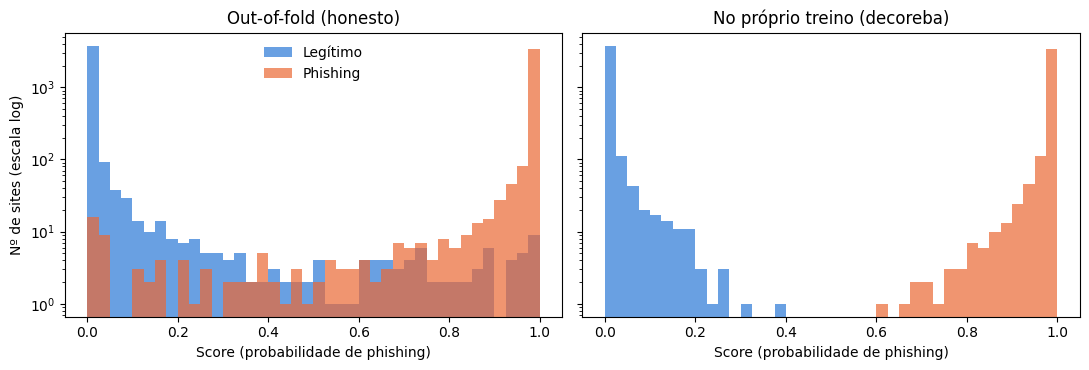

In [2]:
# Out-of-fold: cada linha recebe score de um modelo que não a viu
scores_oof = train.oof_scores(X_tr, y_tr)

# "Decoreba": treina no treino inteiro e dá score no próprio treino
modelo = models.get_candidates()[config.FINAL_MODEL].fit(X_tr, y_tr)
scores_treino = modelo.predict_proba(X_tr)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, (titulo, s) in zip(axes, [("Out-of-fold (honesto)", scores_oof),
                                  ("No próprio treino (decoreba)", scores_treino)]):
    ax.hist(s[y_tr == 0], bins=bins, alpha=.7, color="#2a78d6", label="Legítimo")
    ax.hist(s[y_tr == 1], bins=bins, alpha=.7, color="#eb6834", label="Phishing")
    ax.set(title=titulo, xlabel="Score (probabilidade de phishing)", yscale="log")
axes[0].set_ylabel("Nº de sites (escala log)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

No próprio treino quase tudo fica colado em 0 ou 1: escolher o limiar ali
seria escolher num mundo onde o modelo quase não erra. Os scores out-of-fold
mostram a zona cinzenta real, onde os erros acontecem — são o substituto
honesto do teste.

,limiar,fp,fn,custo
"limiar 0,5",0.500,67,60,667.0
limiar ótimo,0.105,156,25,406.0


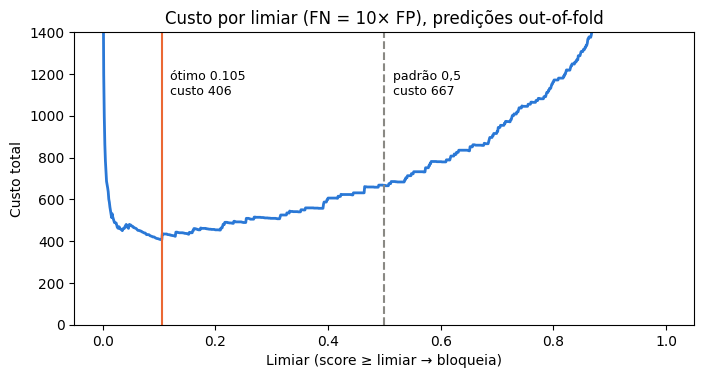

In [3]:
curva = evaluate.cost_curve(y_tr, scores_oof)
limiar = evaluate.best_threshold(y_tr, scores_oof)

padrao = evaluate.confusion_at(y_tr, scores_oof, 0.5)
otimo = evaluate.confusion_at(y_tr, scores_oof, limiar)
display(pd.DataFrame([padrao, otimo], index=["limiar 0,5", "limiar ótimo"]))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curva["limiar"], curva["custo"], color="#2a78d6", lw=2)
ax.axvline(0.5, color="#8a8984", ls="--", lw=1.5)
ax.axvline(limiar, color="#eb6834", lw=1.5)
ax.annotate(f"padrão 0,5\ncusto {padrao['custo']:.0f}", (0.5, 1100),
            xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.annotate(f"ótimo {limiar:.3f}\ncusto {otimo['custo']:.0f}",
            (limiar, 1100), xytext=(6, 0), textcoords="offset points", fontsize=9)
ax.set(xlabel="Limiar (score ≥ limiar → bloqueia)", ylabel="Custo total",
       ylim=(0, 1400), title="Custo por limiar (FN = 10× FP), predições out-of-fold")
plt.show()

O limiar ótimo cai para perto de 0,1: o modelo aceita bloquear mais sites
legítimos para deixar passar bem menos phishing. Com FN valendo 10, essa troca
reduz o custo total em cerca de 40%.

Como o limiar sai de `config.CostMatrix`, mudar a premissa de negócio
(ex.: FN = 5× FP) reajusta tudo sem tocar em código de modelagem.